# Scratch experiment: `dspy.ChainOfThought(IdentifyGroups)` against the no-DSPy fine-tuned checkpoint

`inference_sft.ipynb` argued that wrapping the fine-tuned checkpoint in `dspy.ChainOfThought`
(instead of plain `dspy.Predict`) *should* be harmless with `PlainJSONAdapter`, since
`PlainJSONAdapter.format()` ignores the signature entirely -- the extra `reasoning` output field
ChainOfThought prepends only affects `parse()`'s output-field filter, not what's actually sent to
the model. This notebook just runs it and looks at the raw results, instead of only reasoning
about it -- a scratch/exploration notebook, not meant to be polished.

Runs both `dspy.Predict(IdentifyGroups)` and `get_dspy_cot('llm', 'p1')`'s
`dspy.ChainOfThought(IdentifyGroups)` side by side on the same inputs, printing the exact messages
sent to the model and the raw completion for each, so any difference is directly visible.

**Requirements**: `py10-dspy` conda kernel, a free GPU.

In [1]:
import json
import os
import uuid
import datetime

os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pin to a single free GPU (see nvidia-smi)

import dspy
import matplotlib.pyplot as plt
from PIL import Image
from vllm import LLM, SamplingParams

from prompts import IdentifyGroups
from utils import get_dspy_cot, get_frame_bboxes, save_frame
from sft_data_utils import build_sft_examples

/lp-dev/anaconda3/envs/py10-dspy/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/lp-dev/anaconda3/envs/py10-dspy/lib/python3.10/site-packages/transformers/utils/hub.py:110: FutureWarning: Using `TRANSFORMERS_CACHE` is deprecated and will be removed in v5 of Transformers. Use `HF_HOME` instead.
  warnings.warn(


In [2]:
class VLLMOfflineLM(dspy.LM):
    """DSPy-compatible LM wrapper around an in-process (offline) vLLM engine."""

    def __init__(self, model, max_tokens=4096, temperature=0.6, **engine_kwargs):
        super().__init__(model=f"openai/{model}", temperature=temperature, max_tokens=max_tokens)

        self.model_name = model
        self.max_tokens = max_tokens
        self.temperature = temperature
        self.engine = LLM(model=model, trust_remote_code=True, **engine_kwargs)

    def __call__(self, prompt=None, messages=None, **kwargs):
        if messages is None:
            messages = [{"role": "user", "content": prompt}]

        sampling_params = SamplingParams(temperature=self.temperature, max_tokens=self.max_tokens)
        [result] = self.engine.chat(messages, sampling_params=sampling_params, use_tqdm=False)
        text = result.outputs[0].text
        outputs = [text]

        entry = {
            "prompt": prompt,
            "messages": messages,
            "kwargs": kwargs,
            "response": text,
            "outputs": outputs,
            "usage": {
                "prompt_tokens": len(result.prompt_token_ids),
                "completion_tokens": len(result.outputs[0].token_ids),
                "total_tokens": len(result.prompt_token_ids) + len(result.outputs[0].token_ids),
            },
            "cost": None,
            "timestamp": datetime.datetime.now().isoformat(),
            "uuid": str(uuid.uuid4()),
            "model": self.model,
            "response_model": self.model_name,
            "model_type": "chat",
        }
        self.update_history(entry)

        return outputs

In [3]:
SYSTEM_PROMPT = (
    "Given a list of people with their 3D positions, group them into sets where each set "
    "contains people who are close to each other in space. Compute all pairwise distances "
    "between people. Choose a reasonable grouping threshold based on the distribution of "
    "these distances. People belong to the same group if their pairwise distances are below "
    "this threshold. Return only non-empty groups. Do not merge distant people into the same "
    "group. Do not hallucinate non-existent person_id.\n\n"
    "You are given a JSON array of people, each an object with keys 'person_id', 'x', 'y', 'z'.\n"
    "Respond with ONLY a JSON object of the form {\"groups\": [[person_id, ...], ...]} "
    "and no other text. All ids should appear at least once."
)


class PlainJSONAdapter(dspy.Adapter):
    """Reproduces sft_training_llm_nodspy.ipynb's exact prompt/response format."""

    def format(self, signature, demos, inputs):
        return [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": json.dumps(inputs["detections"])},
        ]

    def parse(self, signature, completion):
        fields = json.loads(completion)
        return {k: v for k, v in fields.items() if k in signature.output_fields}

In [4]:
lm = VLLMOfflineLM(
    model='sft_output/qwen2.5-7b-groups-merged-nodspy',
    max_tokens=512,
    temperature=0.0,
)
dspy.configure(lm=lm, adapter=PlainJSONAdapter())

predict = dspy.Predict(IdentifyGroups)
cot, use_direction = get_dspy_cot('llm', 'p1')  # the ChainOfThought module -- this is what we're testing
print(type(cot), 'use_direction:', use_direction)

INFO 07-08 20:34:48 [utils.py:233] non-default args: {'trust_remote_code': True, 'disable_log_stats': True, 'model': 'sft_output/qwen2.5-7b-groups-merged-nodspy'}
INFO 07-08 20:34:48 [model.py:549] Resolved architecture: Qwen2ForCausalLM
INFO 07-08 20:34:48 [model.py:1678] Using max model len 32768
INFO 07-08 20:34:48 [scheduler.py:238] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 07-08 20:34:48 [vllm.py:790] Asynchronous scheduling is enabled.


The tokenizer you are loading from 'sft_output/qwen2.5-7b-groups-merged-nodspy' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


(EngineCore pid=1687879) INFO 07-08 20:34:49 [core.py:105] Initializing a V1 LLM engine (v0.19.0) with config: model='sft_output/qwen2.5-7b-groups-merged-nodspy', speculative_config=None, tokenizer='sft_output/qwen2.5-7b-groups-merged-nodspy', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, tokenizer_revision=None, trust_remote_code=True, dtype=torch.bfloat16, max_seq_len=32768, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=None, enforce_eager=False, enable_return_routed_experts=False, kv_cache_dtype=auto, device_config=cuda, structured_outputs_config=StructuredOutputsConfig(backend='auto', disable_any_whitespace=False, disable_additional_properties=False, reasoning_parser='', reasoning_parser_plugin='', enable_in_reasoning=False), observability_config=ObservabilityConfig(show_hidden_metrics_for_version=None,

(EngineCore pid=1687879) <frozen importlib._bootstrap_external>:1184: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
(EngineCore pid=1687879) <frozen importlib._bootstrap_external>:1184: FutureWarning: The cuda.nvrtc module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.nvrtc module instead.
Loading safetensors checkpoint shards:   0% Completed | 0/4 [00:00<?, ?it/s]
Loading safetensors checkpoint shards:  25% Completed | 1/4 [00:00<00:01,  2.83it/s]
Loading safetensors checkpoint shards:  50% Completed | 2/4 [00:00<00:00,  2.60it/s]
Loading safetensors checkpoint shards:  75% Completed | 3/4 [00:01<00:00,  2.89it/s]
Loading safetensors checkpoint shards: 100% Completed | 4/4 [00:01<00:00,  3.56it/s]
(EngineCore pid=1687879) 


(EngineCore pid=1687879) INFO 07-08 20:34:55 [default_loader.py:384] Loading weights took 1.13 seconds
(EngineCore pid=1687879) INFO 07-08 20:34:56 [gpu_model_runner.py:4820] Model loading took 14.25 GiB memory and 1.724570 seconds
(EngineCore pid=1687879) INFO 07-08 20:34:58 [backends.py:1051] Using cache directory: /home/nvidia/.cache/vllm/torch_compile_cache/0b6ae8ee0e/rank_0_0/backbone for vLLM's torch.compile
(EngineCore pid=1687879) INFO 07-08 20:34:59 [backends.py:1111] Dynamo bytecode transform time: 2.21 s
(EngineCore pid=1687879) INFO 07-08 20:35:01 [backends.py:285] Directly load the compiled graph(s) for compile range (1, 8192) from the cache, took 1.935 s
(EngineCore pid=1687879) INFO 07-08 20:35:01 [decorators.py:303] Directly load AOT compilation from path /home/nvidia/.cache/vllm/torch_compile_cache/torch_aot_compile/20ce487854c415df712a4bd643c22294dcb477fb626070cd34214b0daa732d41/rank_0_0/model
(EngineCore pid=1687879) INFO 07-08 20:35:01 [monitor.py:48] torch.compile 

Capturing CUDA graphs (mixed prefill-decode, PIECEWISE): 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:02<00:00, 22.05it/s]
Capturing CUDA graphs (decode, FULL): 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 35/35 [00:01<00:00, 26.02it/s]


(EngineCore pid=1687879) INFO 07-08 20:35:10 [gpu_model_runner.py:6046] Graph capturing finished in 5 secs, took 0.47 GiB
(EngineCore pid=1687879) INFO 07-08 20:35:10 [gpu_worker.py:597] CUDA graph pool memory: 0.47 GiB (actual), 0.55 GiB (estimated), difference: 0.07 GiB (15.2%).
(EngineCore pid=1687879) INFO 07-08 20:35:10 [core.py:283] init engine (profile, create kv cache, warmup model) took 14.38 seconds
<class 'dspy.predict.chain_of_thought.ChainOfThought'> use_direction: False


## Round 1: held-out example, `Predict` vs. `ChainOfThought` side by side

In [5]:
from utils import inference_wrapper

examples = build_sft_examples(scenario_range=None, require_image=False)
scenario_ids = sorted({e['scenario_idx'] for e in examples})
val_scenarios = set(scenario_ids[-3:])  # same held-out split as sft_training_llm_nodspy.ipynb
val_examples = [e for e in examples if e['scenario_idx'] in val_scenarios]

holdout = val_examples[0]

predict_out = inference_wrapper(lm, predict, holdout['frame_input_data'], mode='llm', prompt='p1')
predict_raw = lm.history[-1]['response']

cot_out = inference_wrapper(lm, cot, holdout['frame_input_data'], mode='llm', prompt='p1')
cot_raw = lm.history[-1]['response']

print('ground truth:         ', holdout['gt_groups'])
print('Predict groups:       ', predict_out['groups'], '| error:', predict_out['error'])
print('ChainOfThought groups:', cot_out['groups'], '| error:', cot_out['error'])
print()
print('Predict raw completion:        ', repr(predict_raw))
print('ChainOfThought raw completion: ', repr(cot_raw))

The tokenizer you are loading from 'sft_output/qwen2.5-7b-groups-merged-nodspy' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


INFO 07-08 20:35:16 [hf.py:314] Detected the chat template content format to be 'string'. You can set `--chat-template-content-format` to override this.
ground truth:          [[11], [45], [68], [41], [40], [18], [24, 26], [208, 13, 14], [287], [1], [39], [282], [281], [234], [5], [95], [94], [93], [233], [6], [9, 10], [192], [196, 139], [8, 98, 7], [42], [193], [43, 44], [236], [235], [170], [168], [72], [166], [167], [176, 175], [67, 65, 64], [25], [47, 46], [60, 189], [52], [28], [56], [66], [59], [55], [54, 58], [53], [51], [19, 20], [162], [144], [15], [32], [30], [288], [102, 110], [23, 22], [16], [17], [34], [29], [33], [138], [4, 2], [142], [3], [259], [256], [253], [96], [145], [197], [97]]
Predict groups:        [[11], [45, 68], [41, 40], [18], [24], [208], [287], [1, 9], [39], [282, 281, 234, 233], [5, 6], [95], [94, 93], [236], [235], [26], [170], [168, 166, 167], [72], [67], [25], [65], [47, 46], [60], [52], [28], [56], [66], [59], [175], [55], [192], [196], [98], [42, 43]

## Round 2: a handful more held-out examples

Quick loop to see if the two ever disagree, or if `ChainOfThought` ever produces something
`Predict` doesn't (malformed JSON, a populated `reasoning`, etc.).

In [6]:
for i, ex in enumerate(val_examples[:10]):
    print(f'--- example {i} (scenario {ex["scenario_idx"]}, frame {ex["frame_key"]}) ---')
    print('ground truth:', ex['gt_groups'])

    p_out = inference_wrapper(lm, predict, ex['frame_input_data'], mode='llm', prompt='p1')
    print('Predict:       ', p_out['groups'] if p_out['error'] is None else f"ERROR -- {p_out['error']}")

    c_out = inference_wrapper(lm, cot, ex['frame_input_data'], mode='llm', prompt='p1')
    print('ChainOfThought:', c_out['groups'] if c_out['error'] is None else f"ERROR -- {c_out['error']}")
    print()

--- example 0 (scenario 24, frame 0) ---
ground truth: [[11], [45], [68], [41], [40], [18], [24, 26], [208, 13, 14], [287], [1], [39], [282], [281], [234], [5], [95], [94], [93], [233], [6], [9, 10], [192], [196, 139], [8, 98, 7], [42], [193], [43, 44], [236], [235], [170], [168], [72], [166], [167], [176, 175], [67, 65, 64], [25], [47, 46], [60, 189], [52], [28], [56], [66], [59], [55], [54, 58], [53], [51], [19, 20], [162], [144], [15], [32], [30], [288], [102, 110], [23, 22], [16], [17], [34], [29], [33], [138], [4, 2], [142], [3], [259], [256], [253], [96], [145], [197], [97]]
Predict:        [[11], [45, 68], [41, 40], [18], [24], [208], [287], [1, 9], [39], [282, 281, 234, 233], [5, 6], [95], [94, 93], [236], [235], [26], [170], [168, 166, 167], [72], [67], [25], [65], [47, 46], [60], [52], [28], [56], [66], [59], [175], [55], [192], [196], [42, 43], [98], [193], [238], [176], [54], [64], [53], [51], [19], [102], [14, 13], [22], [16, 17], [34], [29], [33], [110], [138], [4, 2, 3],

## Round 3: real scenario frame, visualized on the image

Same real-scenario-JSON + frame-image + `get_frame_bboxes` setup `inference.ipynb` uses, instead of
a held-out example from `build_sft_examples`. `get_dspy_cot('llm', 'p1')` (called above) already
gave us `cot` and `use_direction`; here we reuse both `predict` and `cot` on the same real frame and
draw each one's predicted groups on the image with `utils.save_frame`, same as `inference.ipynb`.

In [7]:
scenario_path = '../../gold_SEKAI_900_3/jsons_step5/clip_0004.json'
frame_id = 1
frame_path = '../../gold_SEKAI_900_3/videos_frames/clip_0004/00001.jpeg'

with open(scenario_path, 'r') as f:
    data = json.load(f)

print(data['dataset'], '-', len(data['frames']), 'frames')

mode = 'llm'
prompt_method = 'p1'
depth_method = 'detany_3D'

frame_input_data, personid2bbox = get_frame_bboxes(data, use_direction, depth_method, frame_id, prompt_method)
print(f'{len(frame_input_data)} people detected in frame {frame_id}')

predict_out = inference_wrapper(lm, predict, frame_input_data, mode=mode, image_path=frame_path, prompt=prompt_method)
cot_out = inference_wrapper(lm, cot, frame_input_data, mode=mode, image_path=frame_path, prompt=prompt_method)

print('Predict groups:       ', predict_out['groups'], '| error:', predict_out['error'])
print('ChainOfThought groups:', cot_out['groups'], '| error:', cot_out['error'])

sekai - 50 frames
7 people detected in frame 1
Predict groups:        [[1, 4], [2], [3, 6], [5, 7]] | error: None
ChainOfThought groups: [[1, 4], [2], [3, 6], [5, 7]] | error: None


In [8]:
print(lm.inspect_history(1))





[2026-07-08T20:36:47.869289]

System message:

Given a list of people with their 3D positions, group them into sets where each set contains people who are close to each other in space. Compute all pairwise distances between people. Choose a reasonable grouping threshold based on the distribution of these distances. People belong to the same group if their pairwise distances are below this threshold. Return only non-empty groups. Do not merge distant people into the same group. Do not hallucinate non-existent person_id.

You are given a JSON array of people, each an object with keys 'person_id', 'x', 'y', 'z'.
Respond with ONLY a JSON object of the form {"groups": [[person_id, ...], ...]} and no other text. All ids should appear at least once.


User message:

[{"person_id": 1, "x": -1.6144, "y": 3.4569, "z": 45.1992}, {"person_id": 2, "x": -3.5211, "y": 3.268, "z": 42.3017}, {"person_id": 3, "x": 1.7581, "y": 0.8437, "z": 6.2711}, {"person_id": 4, "x": -1.3298, "y": 3.4409, "z": 45

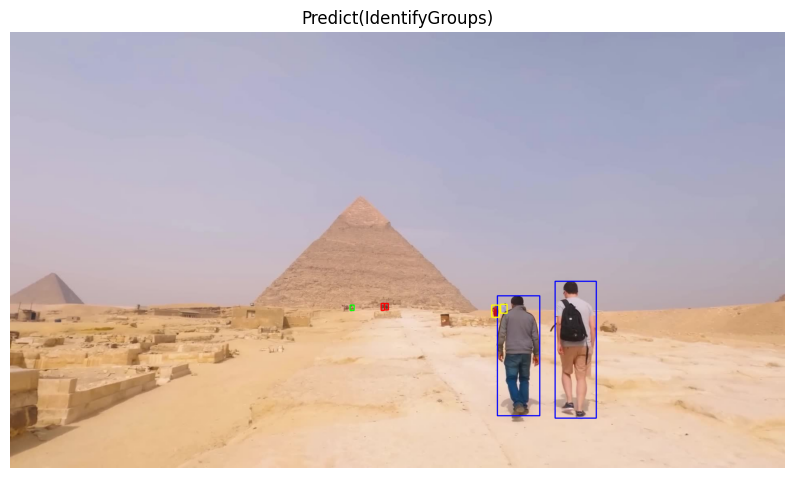

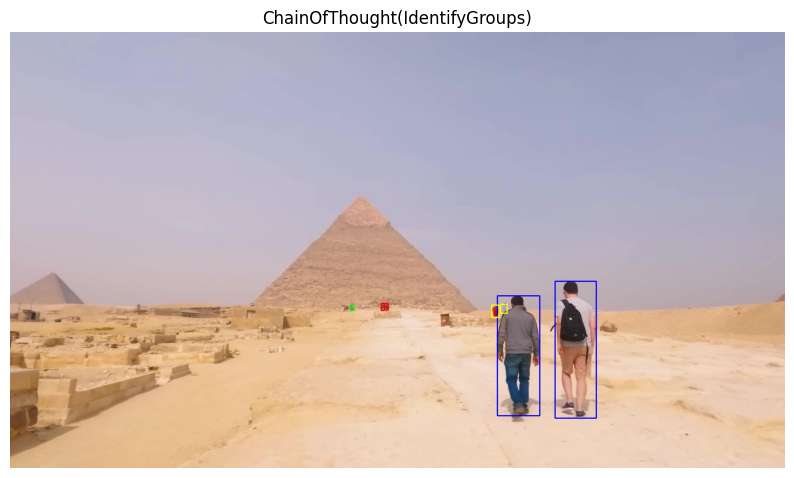

In [9]:
def visualize(output, save_filename, title):
    if output['error'] is not None:
        print(f'skipping visualization for {title!r} -- inference errored:', output['error'])
        return

    output = dict(output)  # don't mutate the caller's dict
    output['frame_id'] = frame_id
    output['id_tobbox'] = personid2bbox

    res_path = 'demo_predictions'
    model_name = lm.model_name  # 'sft_output/qwen2.5-7b-groups-merged-nodspy'

    save_frame(
        output, personid2bbox, res_path, save_filename, frame_path,
        save_image=True, model=model_name, mode=mode,
        depth_method=depth_method, prompt_method=prompt_method, frame_id=frame_id,
    )
    result_path = os.path.join(
        res_path, model_name.split('/')[1], mode, depth_method,
        prompt_method, str(frame_id), save_filename, 'result.png',
    )
    plt.figure(figsize=(10, 6))
    plt.imshow(Image.open(result_path))
    plt.axis('off')
    plt.title(title)
    plt.show()


visualize(predict_out, 'clip_0004_sft_predict', 'Predict(IdentifyGroups)')
visualize(cot_out, 'clip_0004_sft_cot', 'ChainOfThought(IdentifyGroups)')

## Round 4: what if we use DSPy's stock `JSONAdapter` instead?

`dspy.JSONAdapter()` builds its own system message from `IdentifyGroups`'s docstring/field
descriptions plus a JSON-schema instruction -- not the notebook's hand-written `SYSTEM_PROMPT`
verbatim. Since the checkpoint was fine-tuned on that exact hand-written prompt, this is expected to
be a mismatch; this cell just runs it to see what actually happens.

`dspy.context(adapter=...)` temporarily overrides the adapter for calls inside the `with` block only
-- it does not touch the `PlainJSONAdapter` configured globally above, so everything before/after
this cell is unaffected.

In [10]:
with dspy.context(adapter=dspy.JSONAdapter()):
    json_predict_out = inference_wrapper(lm, predict, holdout['frame_input_data'], mode='llm', prompt='p1')
    json_predict_messages = lm.history[-1]['messages']
    json_predict_raw = lm.history[-1]['response']

    json_cot_out = inference_wrapper(lm, cot, holdout['frame_input_data'], mode='llm', prompt='p1')
    json_cot_raw = lm.history[-1]['response']

print('ground truth:               ', holdout['gt_groups'])
print('PlainJSONAdapter (Predict): ', predict_out['groups'], '| error:', predict_out['error'])
print('JSONAdapter (Predict):      ', json_predict_out['groups'], '| error:', json_predict_out['error'])
print('JSONAdapter (ChainOfThought):', json_cot_out['groups'], '| error:', json_cot_out['error'])
print()
print('messages JSONAdapter sent for Predict:')
print(json.dumps(json_predict_messages, indent=2))
print()
print('raw completion (Predict):        ', repr(json_predict_raw))
print('raw completion (ChainOfThought): ', repr(json_cot_raw))

ground truth:                [[11], [45], [68], [41], [40], [18], [24, 26], [208, 13, 14], [287], [1], [39], [282], [281], [234], [5], [95], [94], [93], [233], [6], [9, 10], [192], [196, 139], [8, 98, 7], [42], [193], [43, 44], [236], [235], [170], [168], [72], [166], [167], [176, 175], [67, 65, 64], [25], [47, 46], [60, 189], [52], [28], [56], [66], [59], [55], [54, 58], [53], [51], [19, 20], [162], [144], [15], [32], [30], [288], [102, 110], [23, 22], [16], [17], [34], [29], [33], [138], [4, 2], [142], [3], [259], [256], [253], [96], [145], [197], [97]]
PlainJSONAdapter (Predict):  [[1, 4], [2], [3, 6], [5, 7]] | error: None
JSONAdapter (Predict):       [[11], [45, 68], [41, 40], [18], [24], [208], [287], [1, 9], [39], [282, 281, 234, 233], [5, 6], [95], [94, 93], [236], [192], [196], [8], [42, 43], [193], [98], [235], [26], [170], [168, 166, 167], [72], [67], [25], [65], [47, 46], [60], [52], [28], [56], [66], [59], [175], [55], [189], [54], [64], [53], [51], [58], [5], [19], [162],

---

Take whatever you observe here with a grain of salt -- this is just for poking at the behavior, not
a rigorous comparison. If `ChainOfThought` turns out to behave identically to `Predict` (expected,
per the reasoning in `inference_sft.ipynb`), stick with plain `dspy.Predict(IdentifyGroups)`
elsewhere since it's the simpler, exact match to how the checkpoint was actually trained.

## Round 5: same tests, but the GRPO-merged checkpoint

`sft_output/qwen2.5-7b-groups-grpo-merged` is the further RL (GRPO/RLVR, see
`rl_training_llm_nodspy.ipynb`/`.py`) stage on top of the no-DSPy SFT checkpoint tested above. It
was still trained on the exact same hand-written `SYSTEM_PROMPT`/plain-JSON format (`mode='llm'`,
text-only 3D positions), so `PlainJSONAdapter` still applies. This section repeats Rounds 1-4
against this checkpoint, loaded as a second, separate vLLM engine on a different free GPU so both
checkpoints stay resident side by side and results are directly comparable in this same notebook
run.

In [11]:
os.environ['CUDA_VISIBLE_DEVICES'] = '2'  # separate free GPU so this engine coexists with `lm` above

lm_grpo = VLLMOfflineLM(
    model='sft_output/qwen2.5-7b-groups-grpo-merged',
    max_tokens=512,
    temperature=0.0,
)
dspy.configure(lm=lm_grpo, adapter=PlainJSONAdapter())

predict_grpo = dspy.Predict(IdentifyGroups)
cot_grpo, use_direction_grpo = get_dspy_cot('llm', 'p1')
print(type(cot_grpo), 'use_direction:', use_direction_grpo)

INFO 07-08 20:36:57 [utils.py:233] non-default args: {'trust_remote_code': True, 'disable_log_stats': True, 'model': 'sft_output/qwen2.5-7b-groups-grpo-merged'}
INFO 07-08 20:36:57 [model.py:549] Resolved architecture: Qwen2ForCausalLM
INFO 07-08 20:36:57 [model.py:1678] Using max model len 32768


The tokenizer you are loading from 'sft_output/qwen2.5-7b-groups-grpo-merged' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


(EngineCore pid=1691870) INFO 07-08 20:36:58 [core.py:105] Initializing a V1 LLM engine (v0.19.0) with config: model='sft_output/qwen2.5-7b-groups-grpo-merged', speculative_config=None, tokenizer='sft_output/qwen2.5-7b-groups-grpo-merged', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, tokenizer_revision=None, trust_remote_code=True, dtype=torch.bfloat16, max_seq_len=32768, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=None, enforce_eager=False, enable_return_routed_experts=False, kv_cache_dtype=auto, device_config=cuda, structured_outputs_config=StructuredOutputsConfig(backend='auto', disable_any_whitespace=False, disable_additional_properties=False, reasoning_parser='', reasoning_parser_plugin='', enable_in_reasoning=False), observability_config=ObservabilityConfig(show_hidden_metrics_for_version=None, otl

(EngineCore pid=1691870) <frozen importlib._bootstrap_external>:1184: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
(EngineCore pid=1691870) <frozen importlib._bootstrap_external>:1184: FutureWarning: The cuda.nvrtc module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.nvrtc module instead.
Loading safetensors checkpoint shards:   0% Completed | 0/4 [00:00<?, ?it/s]
Loading safetensors checkpoint shards:  25% Completed | 1/4 [00:00<00:01,  2.01it/s]
Loading safetensors checkpoint shards:  50% Completed | 2/4 [00:01<00:01,  1.99it/s]
Loading safetensors checkpoint shards:  75% Completed | 3/4 [00:01<00:00,  2.07it/s]
Loading safetensors checkpoint shards: 100% Completed | 4/4 [00:01<00:00,  2.95it/s]
Loading safetensors checkpoint shards: 100% Completed | 4/4 [00:01<00:00,  2.52it/s]
(EngineCore pid=1691870) 


(EngineCore pid=1691870) INFO 07-08 20:37:06 [default_loader.py:384] Loading weights took 1.59 seconds
(EngineCore pid=1691870) INFO 07-08 20:37:07 [gpu_model_runner.py:4820] Model loading took 14.25 GiB memory and 2.219275 seconds
(EngineCore pid=1691870) INFO 07-08 20:37:12 [backends.py:1051] Using cache directory: /home/nvidia/.cache/vllm/torch_compile_cache/e8ead1baa3/rank_0_0/backbone for vLLM's torch.compile
(EngineCore pid=1691870) INFO 07-08 20:37:12 [backends.py:1111] Dynamo bytecode transform time: 5.11 s
(EngineCore pid=1691870) INFO 07-08 20:37:13 [backends.py:372] Cache the graph of compile range (1, 8192) for later use
(EngineCore pid=1691870) INFO 07-08 20:37:15 [backends.py:390] Compiling a graph for compile range (1, 8192) takes 2.13 s
(EngineCore pid=1691870) INFO 07-08 20:37:17 [decorators.py:640] saved AOT compiled function to /home/nvidia/.cache/vllm/torch_compile_cache/torch_aot_compile/8e412e8b521cb6b6e264360450fc05bc45d124af808f3e844fb150c9e91cf659/rank_0_0/mode

Capturing CUDA graphs (mixed prefill-decode, PIECEWISE): 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:01<00:00, 25.95it/s]
Capturing CUDA graphs (decode, FULL): 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 35/35 [00:01<00:00, 32.27it/s]


(EngineCore pid=1691870) INFO 07-08 20:37:24 [gpu_model_runner.py:6046] Graph capturing finished in 4 secs, took 0.47 GiB
(EngineCore pid=1691870) INFO 07-08 20:37:24 [gpu_worker.py:597] CUDA graph pool memory: 0.47 GiB (actual), 0.55 GiB (estimated), difference: 0.07 GiB (15.2%).
(EngineCore pid=1691870) INFO 07-08 20:37:24 [core.py:283] init engine (profile, create kv cache, warmup model) took 17.26 seconds
<class 'dspy.predict.chain_of_thought.ChainOfThought'> use_direction: False


In [12]:
predict_grpo_out = inference_wrapper(lm_grpo, predict_grpo, holdout['frame_input_data'], mode='llm', prompt='p1')
predict_grpo_raw = lm_grpo.history[-1]['response']

cot_grpo_out = inference_wrapper(lm_grpo, cot_grpo, holdout['frame_input_data'], mode='llm', prompt='p1')
cot_grpo_raw = lm_grpo.history[-1]['response']

print('ground truth:              ', holdout['gt_groups'])
print('Predict groups (GRPO):     ', predict_grpo_out['groups'], '| error:', predict_grpo_out['error'])
print('ChainOfThought groups (GRPO):', cot_grpo_out['groups'], '| error:', cot_grpo_out['error'])
print()
print('Predict raw completion (GRPO):        ', repr(predict_grpo_raw))
print('ChainOfThought raw completion (GRPO): ', repr(cot_grpo_raw))

The tokenizer you are loading from 'sft_output/qwen2.5-7b-groups-grpo-merged' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


ground truth:               [[11], [45], [68], [41], [40], [18], [24, 26], [208, 13, 14], [287], [1], [39], [282], [281], [234], [5], [95], [94], [93], [233], [6], [9, 10], [192], [196, 139], [8, 98, 7], [42], [193], [43, 44], [236], [235], [170], [168], [72], [166], [167], [176, 175], [67, 65, 64], [25], [47, 46], [60, 189], [52], [28], [56], [66], [59], [55], [54, 58], [53], [51], [19, 20], [162], [144], [15], [32], [30], [288], [102, 110], [23, 22], [16], [17], [34], [29], [33], [138], [4, 2], [142], [3], [259], [256], [253], [96], [145], [197], [97]]
Predict groups (GRPO):      [[11], [45, 68], [41, 40], [18], [24], [208], [287], [1, 9], [39], [282, 281, 234, 233], [5, 6], [95], [94, 93], [192], [196], [8], [42, 43], [98], [236], [235], [26], [170], [168], [72], [166], [167], [176], [67], [25], [65], [47, 46], [60], [52], [28], [56], [66], [59], [175], [55], [189], [54], [64], [53], [51], [58], [19], [162], [144], [15], [32, 30], [13], [288], [20], [102], [23, 22], [14], [16, 17], 

In [13]:
for i, ex in enumerate(val_examples[:10]):
    print(f'--- example {i} (scenario {ex["scenario_idx"]}, frame {ex["frame_key"]}) ---')
    print('ground truth:', ex['gt_groups'])

    p_out = inference_wrapper(lm_grpo, predict_grpo, ex['frame_input_data'], mode='llm', prompt='p1')
    print('Predict (GRPO):       ', p_out['groups'] if p_out['error'] is None else f"ERROR -- {p_out['error']}")

    c_out = inference_wrapper(lm_grpo, cot_grpo, ex['frame_input_data'], mode='llm', prompt='p1')
    print('ChainOfThought (GRPO):', c_out['groups'] if c_out['error'] is None else f"ERROR -- {c_out['error']}")
    print()

--- example 0 (scenario 24, frame 0) ---
ground truth: [[11], [45], [68], [41], [40], [18], [24, 26], [208, 13, 14], [287], [1], [39], [282], [281], [234], [5], [95], [94], [93], [233], [6], [9, 10], [192], [196, 139], [8, 98, 7], [42], [193], [43, 44], [236], [235], [170], [168], [72], [166], [167], [176, 175], [67, 65, 64], [25], [47, 46], [60, 189], [52], [28], [56], [66], [59], [55], [54, 58], [53], [51], [19, 20], [162], [144], [15], [32], [30], [288], [102, 110], [23, 22], [16], [17], [34], [29], [33], [138], [4, 2], [142], [3], [259], [256], [253], [96], [145], [197], [97]]
Predict (GRPO):        [[11], [45, 68], [41, 40], [18], [24], [208], [287], [1, 9], [39], [282, 281, 234, 233], [5, 6], [95], [94, 93], [192], [196], [8], [42, 43], [98], [236], [235], [26], [170], [168], [72], [166], [167], [176], [67], [25], [65], [47, 46], [60], [52], [28], [56], [66], [59], [175], [55], [189], [54], [64], [53], [51], [58], [19], [162], [15], [32, 30], [13], [288], [20], [102], [23, 22], [

In [14]:
frame_input_data, personid2bbox = get_frame_bboxes(data, use_direction_grpo, depth_method, frame_id, prompt_method)
print(f'{len(frame_input_data)} people detected in frame {frame_id}')

predict_grpo_frame_out = inference_wrapper(lm_grpo, predict_grpo, frame_input_data, mode=mode, image_path=frame_path, prompt=prompt_method)
cot_grpo_frame_out = inference_wrapper(lm_grpo, cot_grpo, frame_input_data, mode=mode, image_path=frame_path, prompt=prompt_method)

print('Predict groups (GRPO):       ', predict_grpo_frame_out['groups'], '| error:', predict_grpo_frame_out['error'])
print('ChainOfThought groups (GRPO):', cot_grpo_frame_out['groups'], '| error:', cot_grpo_frame_out['error'])

7 people detected in frame 1
Predict groups (GRPO):        [[1, 4], [2], [3, 6], [5, 7]] | error: None
ChainOfThought groups (GRPO): [[1, 4], [2], [3, 6], [5, 7]] | error: None


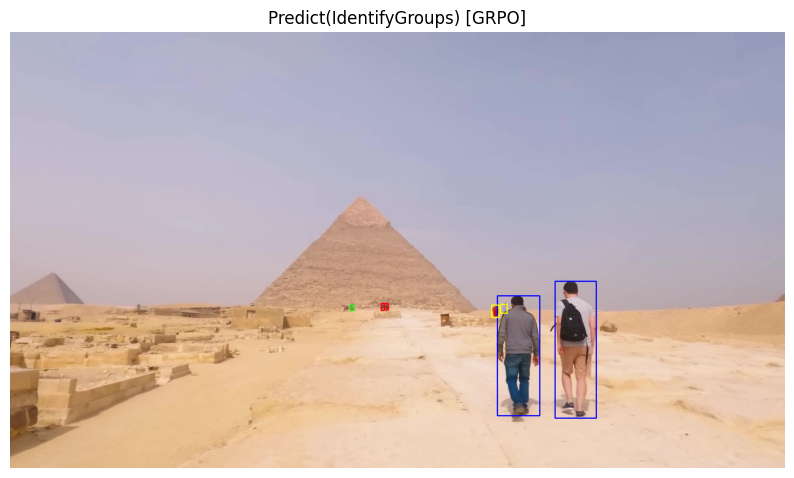

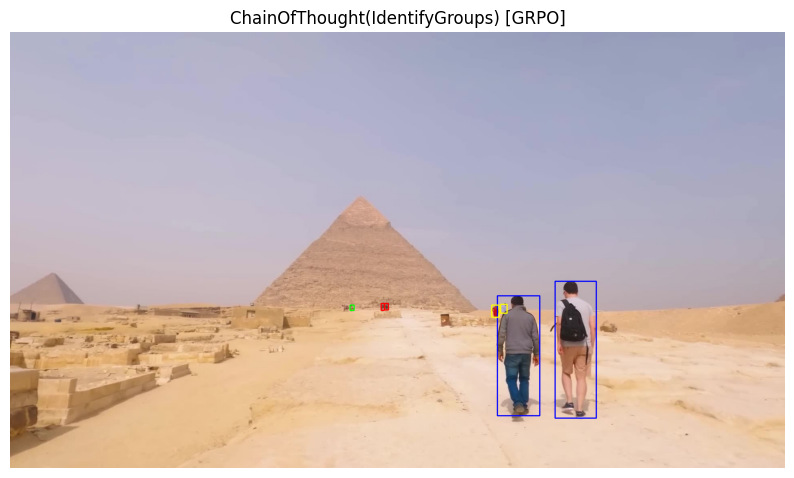

In [15]:
def visualize_grpo(output, save_filename, title):
    if output['error'] is not None:
        print(f'skipping visualization for {title!r} -- inference errored:', output['error'])
        return

    output = dict(output)  # don't mutate the caller's dict
    output['frame_id'] = frame_id
    output['id_tobbox'] = personid2bbox

    res_path = 'demo_predictions'
    model_name = lm_grpo.model_name  # 'sft_output/qwen2.5-7b-groups-grpo-merged'

    save_frame(
        output, personid2bbox, res_path, save_filename, frame_path,
        save_image=True, model=model_name, mode=mode,
        depth_method=depth_method, prompt_method=prompt_method, frame_id=frame_id,
    )
    result_path = os.path.join(
        res_path, model_name.split('/')[1], mode, depth_method,
        prompt_method, str(frame_id), save_filename, 'result.png',
    )
    plt.figure(figsize=(10, 6))
    plt.imshow(Image.open(result_path))
    plt.axis('off')
    plt.title(title)
    plt.show()


visualize_grpo(predict_grpo_frame_out, 'clip_0004_grpo_predict', 'Predict(IdentifyGroups) [GRPO]')
visualize_grpo(cot_grpo_frame_out, 'clip_0004_grpo_cot', 'ChainOfThought(IdentifyGroups) [GRPO]')

### Round 5, cont.: stock `JSONAdapter` against the GRPO checkpoint

Same check as Round 4, but for `lm_grpo`. `dspy.context(adapter=...)` only overrides the adapter
inside the `with` block, so it doesn't disturb the globally configured `PlainJSONAdapter`.

In [16]:
with dspy.context(lm=lm_grpo, adapter=dspy.JSONAdapter()):
    json_predict_grpo_out = inference_wrapper(lm_grpo, predict_grpo, holdout['frame_input_data'], mode='llm', prompt='p1')
    json_predict_grpo_messages = lm_grpo.history[-1]['messages']
    json_predict_grpo_raw = lm_grpo.history[-1]['response']

    json_cot_grpo_out = inference_wrapper(lm_grpo, cot_grpo, holdout['frame_input_data'], mode='llm', prompt='p1')
    json_cot_grpo_raw = lm_grpo.history[-1]['response']

print('ground truth:                      ', holdout['gt_groups'])
print('PlainJSONAdapter (Predict, GRPO):  ', predict_grpo_out['groups'], '| error:', predict_grpo_out['error'])
print('JSONAdapter (Predict, GRPO):       ', json_predict_grpo_out['groups'], '| error:', json_predict_grpo_out['error'])
print('JSONAdapter (ChainOfThought, GRPO):', json_cot_grpo_out['groups'], '| error:', json_cot_grpo_out['error'])
print()
print('messages JSONAdapter sent for Predict (GRPO):')
print(json.dumps(json_predict_grpo_messages, indent=2))
print()
print('raw completion (Predict, GRPO):        ', repr(json_predict_grpo_raw))
print('raw completion (ChainOfThought, GRPO): ', repr(json_cot_grpo_raw))

ground truth:                       [[11], [45], [68], [41], [40], [18], [24, 26], [208, 13, 14], [287], [1], [39], [282], [281], [234], [5], [95], [94], [93], [233], [6], [9, 10], [192], [196, 139], [8, 98, 7], [42], [193], [43, 44], [236], [235], [170], [168], [72], [166], [167], [176, 175], [67, 65, 64], [25], [47, 46], [60, 189], [52], [28], [56], [66], [59], [55], [54, 58], [53], [51], [19, 20], [162], [144], [15], [32], [30], [288], [102, 110], [23, 22], [16], [17], [34], [29], [33], [138], [4, 2], [142], [3], [259], [256], [253], [96], [145], [197], [97]]
PlainJSONAdapter (Predict, GRPO):   [[11], [45, 68], [41, 40], [18], [24], [208], [287], [1, 9], [39], [282, 281, 234, 233], [5, 6], [95], [94, 93], [192], [196], [8], [42, 43], [98], [236], [235], [26], [170], [168], [72], [166], [167], [176], [67], [25], [65], [47, 46], [60], [52], [28], [56], [66], [59], [175], [55], [189], [54], [64], [53], [51], [58], [19], [162], [144], [15], [32, 30], [13], [288], [20], [102], [23, 22], 